## 1. Import Library & Pengaturan Tampilan

`pandas` untuk mengolah data, `matplotlib` dan `seaborn` untuk membuat grafik. Tema dan palet warna diatur di awal supaya semua grafik konsisten.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13

PALET = "viridis"

## 2. Load Data

Data dibaca dari file Excel (sheet `Data Bersih`) yang berisi **150 baris** pencatatan. Saat sel di bawah dijalankan di Google Colab, akan muncul tombol *Choose Files*, lalu pilih file `.xlsx` dataset sampah kampus.

In [2]:
from google.colab import files
uploaded = files.upload()

FILE = next(iter(uploaded))
df = pd.read_excel(FILE, sheet_name="Data Bersih")
df.head(10)


Saving Data Sampah Kampus 2026.xlsx to Data Sampah Kampus 2026.xlsx


,ID,Tanggal,Lokasi,Jenis Sampah,Berat (kg),Jumlah,Kondisi,Cuaca,Aktivitas
0,1,2026-09-20,Gedung A,Plastik,2.50,35,Penuh,Cerah,Kuliah
1,2,2026-09-20,Gedung A,Plastik,2.80,41,Penuh,Cerah,Kuliah
2,3,2026-09-20,Kantin,Organik,9.49,82,Meluber,Hujan,Istirahat
3,4,2026-09-20,Gedung A,Plastik,3.50,75,Penuh,Mendung,Kuliah
4,5,2026-09-20,Kantin,Organik,7.51,53,Meluber,Hujan,Istirahat
5,6,2026-09-20,Gedung A,Logam,2.76,14,Sedang,Cerah,Kuliah
6,7,2026-09-20,Gedung B,Plastik,3.37,154,Meluber,Cerah,Acara
7,8,2026-09-20,Gedung B,Kertas,2.71,20,Kosong,Cerah,Kuliah
8,9,2026-09-20,Gedung C,Kertas,2.32,6,Kosong,Cerah,Kuliah
9,10,2026-09-21,Kantin,Organik,7.10,56,Meluber,Hujan,Istirahat


## 3. Ringkasan Data

Sebelum membuat grafik, cek dulu ukuran data, tipe kolom, dan statistik deskriptifnya.

In [3]:
print("Jumlah baris & kolom :", df.shape)
print("Rentang tanggal      :", df["Tanggal"].min().date(), "s/d", df["Tanggal"].max().date())
print("Total berat sampah   :", round(df["Berat (kg)"].sum(), 1), "kg")
print("Total item sampah    :", df["Jumlah"].sum())
print("Missing value        :", df.isnull().sum().sum())
print()
df.info()

Jumlah baris & kolom : (150, 9)
Rentang tanggal      : 2026-09-20 s/d 2026-10-09
Total berat sampah   : 685.3 kg
Total item sampah    : 9710
Missing value        : 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ID            150 non-null    int64         
 1   Tanggal       150 non-null    datetime64[ns]
 2   Lokasi        150 non-null    object        
 3   Jenis Sampah  150 non-null    object        
 4   Berat (kg)    150 non-null    float64       
 5   Jumlah        150 non-null    int64         
 6   Kondisi       150 non-null    object        
 7   Cuaca         150 non-null    object        
 8   Aktivitas     150 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 10.7+ KB


In [4]:
df[["Berat (kg)", "Jumlah"]].describe().round(2)

,Berat (kg),Jumlah
count,150.00,150.00
mean,4.57,64.73
std,2.35,39.93
min,1.10,6.00
25%,2.72,28.75
50%,3.84,58.50
75%,6.51,91.75
max,10.57,184.00


**Keterangan:** data terdiri dari **150 baris** pencatatan selama 20 hari (20 September sampai 9 Oktober 2026) tanpa *missing value*, sehingga langsung bisa divisualisasikan. Total sampah yang tercatat adalah **685,3 kg** (9.710 item).
Rata-rata berat per pencatatan sekitar 4,57 kg dengan median 3,84 kg, dan sebarannya cukup lebar (1,1 kg sampai 10,57 kg). Rata-rata yang lebih tinggi dari median menandakan sebagian pencatatan berbobot besar menarik rata-rata ke atas.

## 4. Total Berat Sampah per Lokasi

**Tujuan:** mengetahui lokasi mana yang menghasilkan sampah paling banyak.

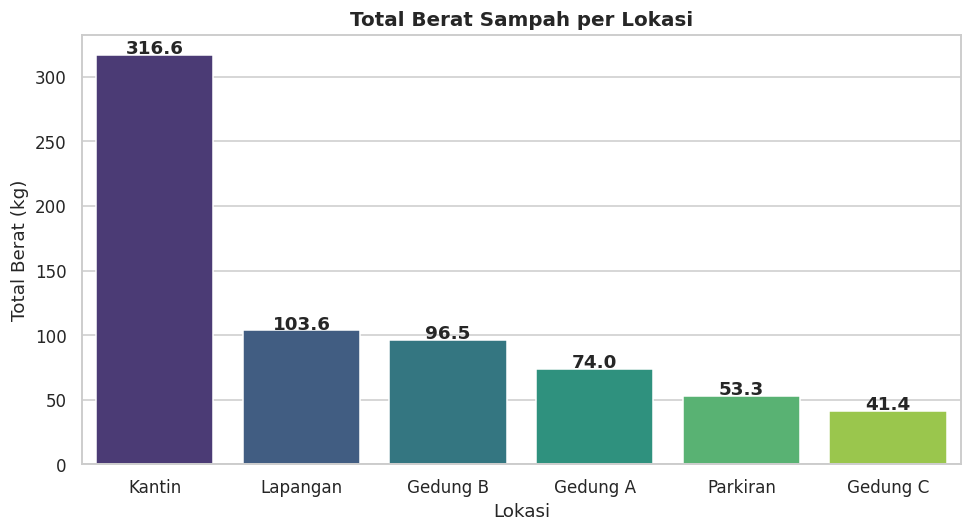

In [5]:
per_lokasi = df.groupby("Lokasi")["Berat (kg)"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=per_lokasi.index, y=per_lokasi.values, palette=PALET, hue=per_lokasi.index, legend=False, ax=ax)
for i, v in enumerate(per_lokasi.values):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontweight="bold")
ax.set_title("Total Berat Sampah per Lokasi")
ax.set_xlabel("Lokasi")
ax.set_ylabel("Total Berat (kg)")
plt.tight_layout()
plt.show()

**Keterangan:** **Kantin** adalah penghasil sampah terbesar (316,6 kg atau 46,2% dari total), jauh di atas lokasi lain. Urutan berikutnya: Lapangan (103,6 kg), Gedung B (96,5 kg), Gedung A (74,0 kg), Parkiran (53,3 kg), dan Gedung C (41,4 kg).
Kantin bukan hanya unggul karena paling banyak dicatat (44 pencatatan), tetapi rata-rata per pencatatannya juga tertinggi (7,19 kg), disusul Lapangan (6,09 kg). Lokasi lain rata-rata hanya sekitar 2,4 sampai 3,5 kg per pencatatan. Ini wajar karena kantin adalah pusat aktivitas makan-minum.

## 5. Komposisi Jenis Sampah

**Tujuan:** melihat proporsi tiap jenis sampah berdasarkan berat, dan membandingkannya dengan jumlah kejadian pencatatan.

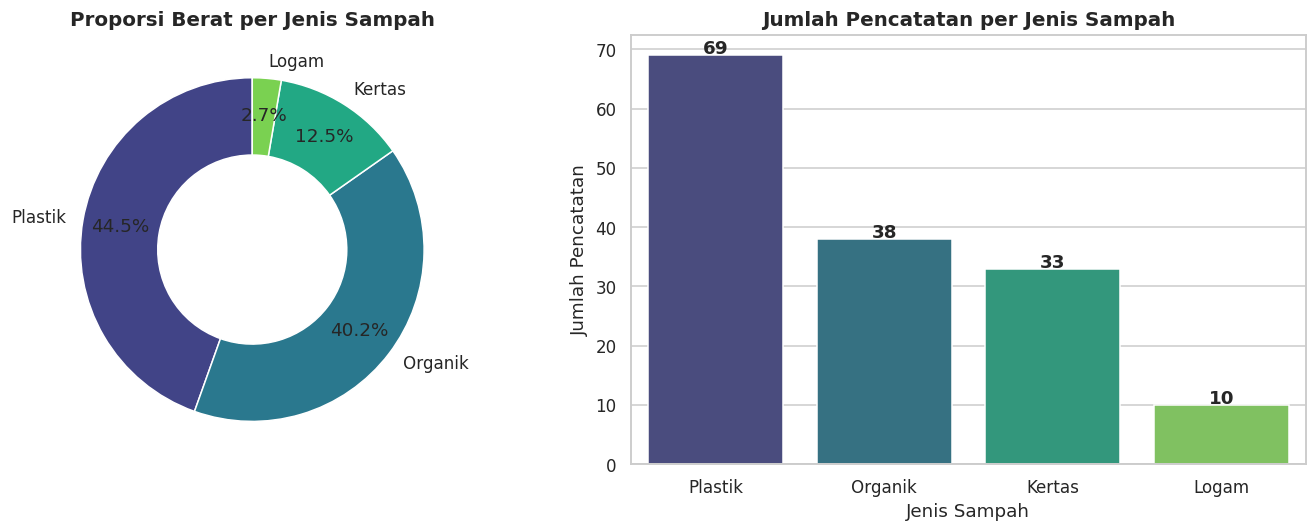

In [6]:
per_jenis = df.groupby("Jenis Sampah")["Berat (kg)"].sum().sort_values(ascending=False)
warna = sns.color_palette(PALET, len(per_jenis))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Donut chart: proporsi berat
axes[0].pie(per_jenis.values, labels=per_jenis.index, colors=warna, autopct="%1.1f%%",
            startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"), pctdistance=0.78)
axes[0].set_title("Proporsi Berat per Jenis Sampah")

# Bar chart: jumlah pencatatan
cnt = df["Jenis Sampah"].value_counts().reindex(per_jenis.index)
sns.barplot(x=cnt.index, y=cnt.values, palette=PALET, hue=cnt.index, legend=False, ax=axes[1])
for i, v in enumerate(cnt.values):
    axes[1].text(i, v + 0.2, str(v), ha="center", fontweight="bold")
axes[1].set_title("Jumlah Pencatatan per Jenis Sampah")
axes[1].set_xlabel("Jenis Sampah")
axes[1].set_ylabel("Jumlah Pencatatan")

plt.tight_layout()
plt.show()

**Keterangan:** **Plastik** (305,3 kg, 44,5%) dan **Organik** (275,6 kg, 40,2%) mendominasi, gabungannya sekitar 85% dari seluruh berat sampah. Kertas menyumbang 86,0 kg (12,5%) dan Logam paling sedikit (18,6 kg, 2,7%).
Plastik paling sering tercatat (69 kali, hampir separuh dari semua pencatatan), tetapi per kejadian Organik jauh lebih berat (rata-rata 7,25 kg dibanding 4,42 kg untuk plastik), karena sampah organik (sisa makanan) memang bobotnya besar.

## 6. Tren Berat Sampah Harian

**Tujuan:** melihat naik-turunnya total sampah dari hari ke hari selama periode pengamatan.

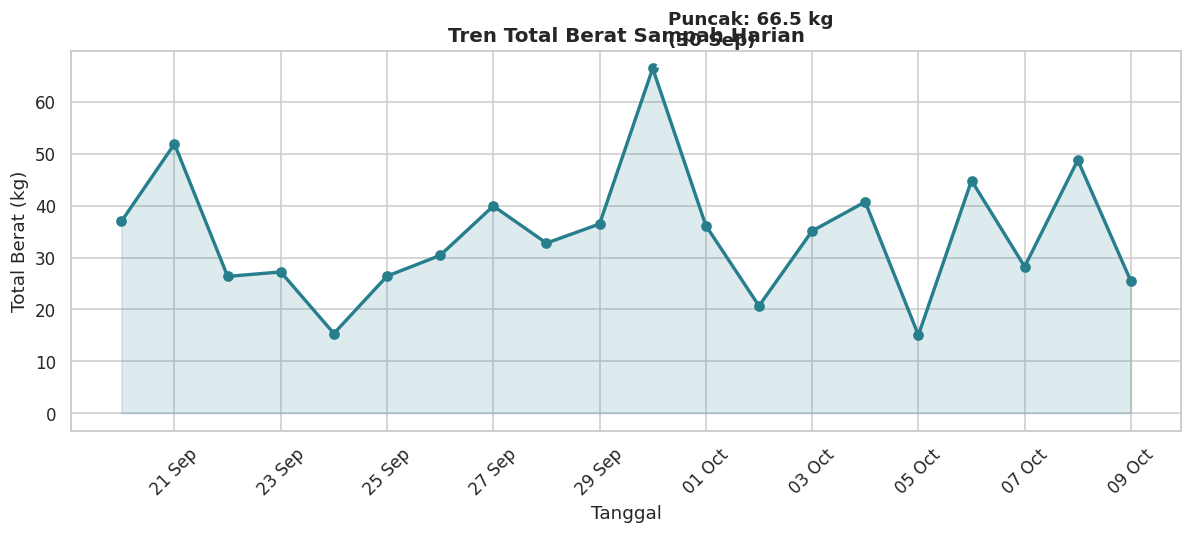

In [7]:
harian = df.groupby("Tanggal")["Berat (kg)"].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(harian.index, harian.values, marker="o", linewidth=2.2, color=sns.color_palette(PALET)[2])
ax.fill_between(harian.index, harian.values, alpha=0.15, color=sns.color_palette(PALET)[2])

# tandai hari dengan sampah tertinggi
puncak = harian.idxmax()
ax.annotate(f"Puncak: {harian.max():.1f} kg\n({puncak:%d %b})",
            xy=(puncak, harian.max()), xytext=(10, 15), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontweight="bold")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Tren Total Berat Sampah Harian")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Total Berat (kg)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Keterangan:** garis menunjukkan total berat sampah per tanggal pencatatan. Titik yang diberi tanda panah adalah **hari dengan sampah terbanyak**, yaitu **30 September (66,45 kg)** dari 11 pencatatan. Hari dengan total terendah adalah 5 Oktober (15,07 kg) dari 5 pencatatan.
Perlu diingat jumlah pencatatan per hari tidak sama (antara 3 sampai 11, rata-rata 7,5), sehingga naik-turunnya garis sebagian dipengaruhi banyaknya titik yang dicatat pada hari itu. Namun pada hari puncak, rata-rata per pencatatannya (sekitar 6,0 kg) juga di atas rata-rata keseluruhan (4,57 kg).

## 7. Pengaruh Cuaca terhadap Berat Sampah

**Tujuan:** membandingkan berat sampah saat cerah, mendung, dan hujan. Box plot dipakai supaya terlihat sebaran, bukan hanya rata-rata.

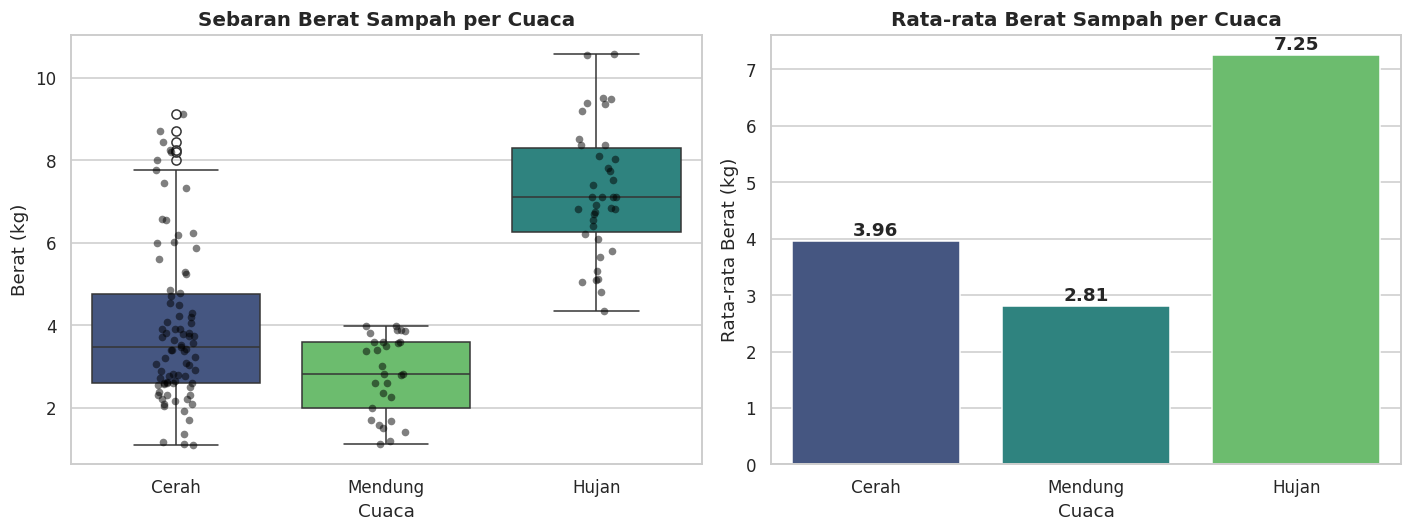

In [8]:
urut_cuaca = ["Cerah", "Mendung", "Hujan"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Cuaca", y="Berat (kg)", order=urut_cuaca, palette=PALET, hue="Cuaca", legend=False, ax=axes[0])
sns.stripplot(data=df, x="Cuaca", y="Berat (kg)", order=urut_cuaca, color="black", alpha=0.5, ax=axes[0])
axes[0].set_title("Sebaran Berat Sampah per Cuaca")

rata = df.groupby("Cuaca")["Berat (kg)"].mean().reindex(urut_cuaca)
sns.barplot(x=rata.index, y=rata.values, palette=PALET, hue=rata.index, legend=False, ax=axes[1])
for i, v in enumerate(rata.values):
    axes[1].text(i, v + 0.1, f"{v:.2f}", ha="center", fontweight="bold")
axes[1].set_title("Rata-rata Berat Sampah per Cuaca")
axes[1].set_ylabel("Rata-rata Berat (kg)")

plt.tight_layout()
plt.show()

**Keterangan:** rata-rata berat saat **hujan (7,25 kg)** sekitar 1,8 kali lipat dibanding cerah (3,96 kg) dan sekitar 2,6 kali lipat dibanding mendung (2,81 kg).

**Catatan kehati-hatian:** ini baru pola, belum tentu sebab-akibat. Dari 38 pencatatan saat hujan, 33 dilakukan di **Kantin** dan 5 di Gedung C, sehingga lokasi ikut memengaruhi hasilnya. Sebagai pembanding, di Kantin sendiri rata-rata saat hujan 7,60 kg dan saat cerah 5,97 kg, jadi selisihnya ada tetapi lebih kecil dari selisih keseluruhan.

## 8. Berat Sampah Berdasarkan Aktivitas

**Tujuan:** melihat aktivitas kampus apa yang paling banyak menghasilkan sampah.

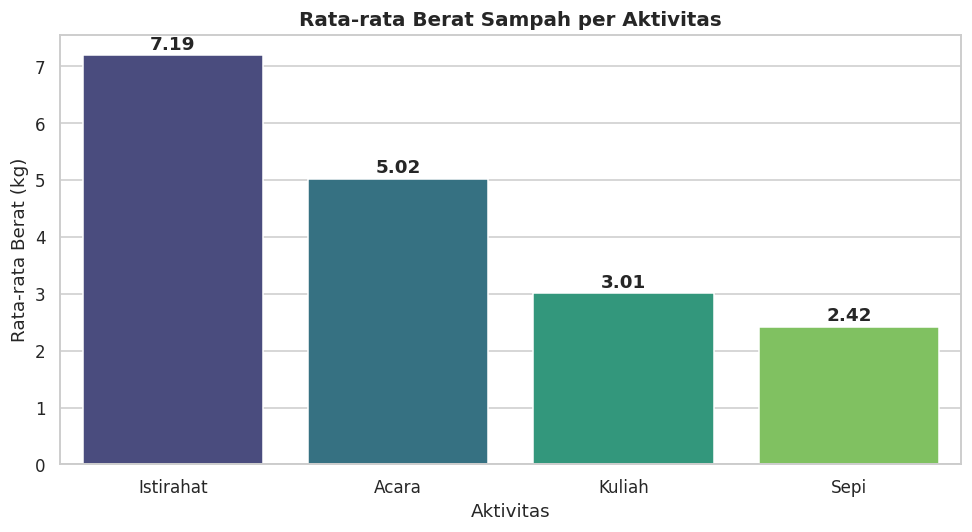

In [9]:
rata_akt = df.groupby("Aktivitas")["Berat (kg)"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=rata_akt.index, y=rata_akt.values, palette=PALET, hue=rata_akt.index, legend=False, ax=ax)
for i, v in enumerate(rata_akt.values):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_title("Rata-rata Berat Sampah per Aktivitas")
ax.set_xlabel("Aktivitas")
ax.set_ylabel("Rata-rata Berat (kg)")
plt.tight_layout()
plt.show()

**Keterangan:** aktivitas **Istirahat** menghasilkan sampah rata-rata paling berat (7,19 kg), disusul **Acara** (5,02 kg). Saat **Kuliah** (3,01 kg) dan **Sepi** (2,42 kg) jauh lebih rendah. Polanya sejalan dengan temuan lokasi: waktu istirahat identik dengan aktivitas makan-minum di kantin.

## 9. Kondisi Tempat Sampah

**Tujuan:** melihat seberapa sering tempat sampah berada dalam kondisi penuh/meluber, secara keseluruhan dan per lokasi.

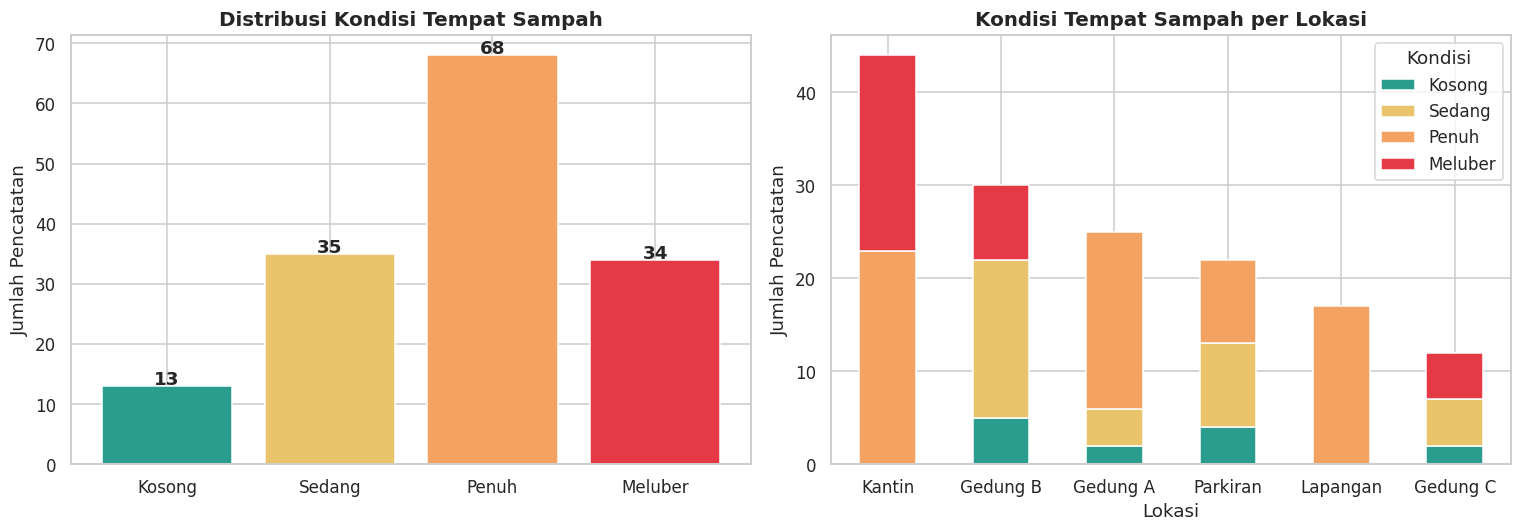

In [10]:
urut_kondisi = ["Kosong", "Sedang", "Penuh", "Meluber"]
warna_kondisi = ["#2a9d8f", "#e9c46a", "#f4a261", "#e63946"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi kondisi keseluruhan
cnt_k = df["Kondisi"].value_counts().reindex(urut_kondisi)
axes[0].bar(cnt_k.index, cnt_k.values, color=warna_kondisi)
for i, v in enumerate(cnt_k.values):
    axes[0].text(i, v + 0.2, str(v), ha="center", fontweight="bold")
axes[0].set_title("Distribusi Kondisi Tempat Sampah")
axes[0].set_ylabel("Jumlah Pencatatan")

# Kondisi per lokasi (stacked)
tab = pd.crosstab(df["Lokasi"], df["Kondisi"]).reindex(columns=urut_kondisi, fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]
tab.plot(kind="bar", stacked=True, color=warna_kondisi, ax=axes[1], edgecolor="white")
axes[1].set_title("Kondisi Tempat Sampah per Lokasi")
axes[1].set_xlabel("Lokasi")
axes[1].set_ylabel("Jumlah Pencatatan")
axes[1].legend(title="Kondisi")
plt.setp(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

**Keterangan:** dari 150 pencatatan, **68 berstatus Penuh** (45,3%) dan **34 Meluber** (22,7%), sehingga sekitar 68% pencatatan berada di kondisi penuh atau lebih. Sisanya 35 Sedang dan hanya 13 yang Kosong (8,7%).
Grafik kanan menunjukkan **Kantin** selalu berada di kondisi Penuh (23) atau Meluber (21), **Lapangan** selalu Penuh (17), dan Gedung A hampir selalu Penuh (19 dari 25). Gedung B dan Gedung C juga sempat Meluber (8 dan 5 kali). Ini bisa jadi dasar menentukan titik yang perlu **tempat sampah tambahan** atau **jadwal pengangkutan lebih sering**.

## 10. Heatmap: Lokasi × Jenis Sampah

**Tujuan:** melihat jenis sampah apa yang dominan di tiap lokasi dalam satu gambar.

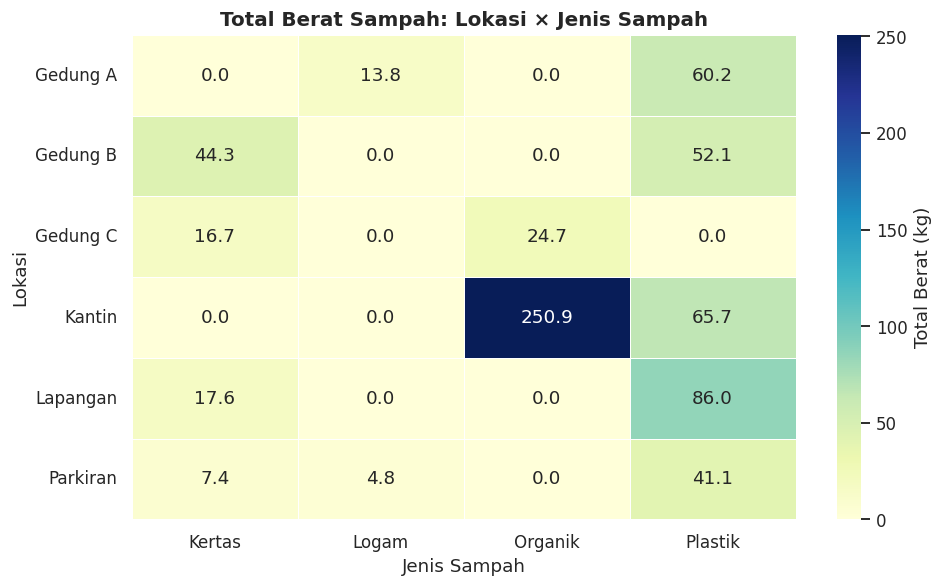

In [11]:
pivot = df.pivot_table(index="Lokasi", columns="Jenis Sampah", values="Berat (kg)", aggfunc="sum", fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Total Berat (kg)"}, ax=ax)
ax.set_title("Total Berat Sampah: Lokasi × Jenis Sampah")
plt.tight_layout()
plt.show()

**Keterangan:** semakin gelap warna sel, semakin berat sampahnya. Heatmap ini memperlihatkan **jenis sampah dominan di setiap lokasi**. Sel yang bernilai 0 berarti jenis tersebut tidak tercatat di lokasi itu.
Sel paling gelap adalah **Kantin × Organik (250,9 kg)**. Sampah organik hanya tercatat di Kantin dan Gedung C (24,7 kg). Plastik dominan di Lapangan (86,0 kg), Gedung A (60,2 kg), dan Parkiran (41,2 kg), sedangkan Gedung B relatif seimbang antara plastik (52,1 kg) dan kertas (44,3 kg). Logam hanya tercatat di Gedung A (13,8 kg) dan Parkiran (4,8 kg).

## 11. Hubungan Berat dan Jumlah Item Sampah

**Tujuan:** mengecek apakah semakin banyak item sampah, semakin berat pula totalnya (korelasi).

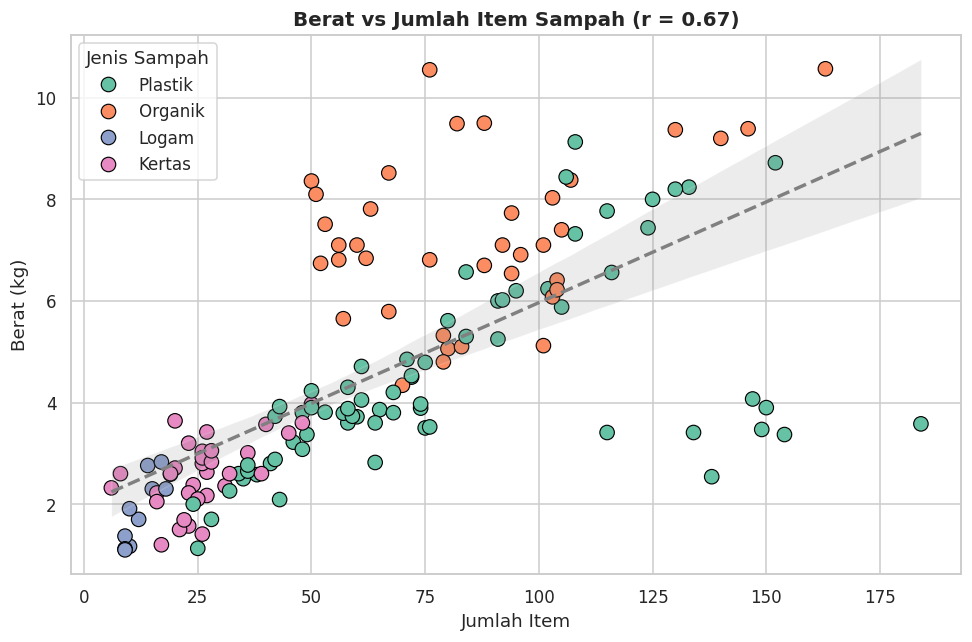

Koefisien korelasi Pearson: 0.675


In [12]:
korelasi = df["Berat (kg)"].corr(df["Jumlah"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="Jumlah", y="Berat (kg)", hue="Jenis Sampah", palette="Set2", s=90, edgecolor="black", ax=ax)
sns.regplot(data=df, x="Jumlah", y="Berat (kg)", scatter=False, color="gray", line_kws={"linestyle": "--"}, ax=ax)
ax.set_title(f"Berat vs Jumlah Item Sampah (r = {korelasi:.2f})")
ax.set_xlabel("Jumlah Item")
ax.set_ylabel("Berat (kg)")
plt.tight_layout()
plt.show()

print(f"Koefisien korelasi Pearson: {korelasi:.3f}")

**Keterangan:** koefisien korelasi sekitar **0,68**, tergolong **positif dan cukup kuat**: makin banyak item, cenderung makin berat sampahnya. Warna titik menunjukkan jenis sampah. Titik **Organik** dan **Plastik** berada di area jumlah item dan berat yang tinggi (organik rata-rata 7,25 kg dan 86 item, plastik 4,42 kg dan 79 item), sedangkan **Kertas** (2,60 kg, 26 item) dan **Logam** (1,86 kg, 12 item) mengumpul di area kiri bawah.
Hubungannya tidak sempurna karena berat per item berbeda antar jenis, misalnya ada pencatatan plastik sebanyak 154 item yang beratnya hanya 3,37 kg.

## 12. Distribusi Berat per Jenis Sampah

**Tujuan:** melihat sebaran dan variasi berat tiap jenis sampah.

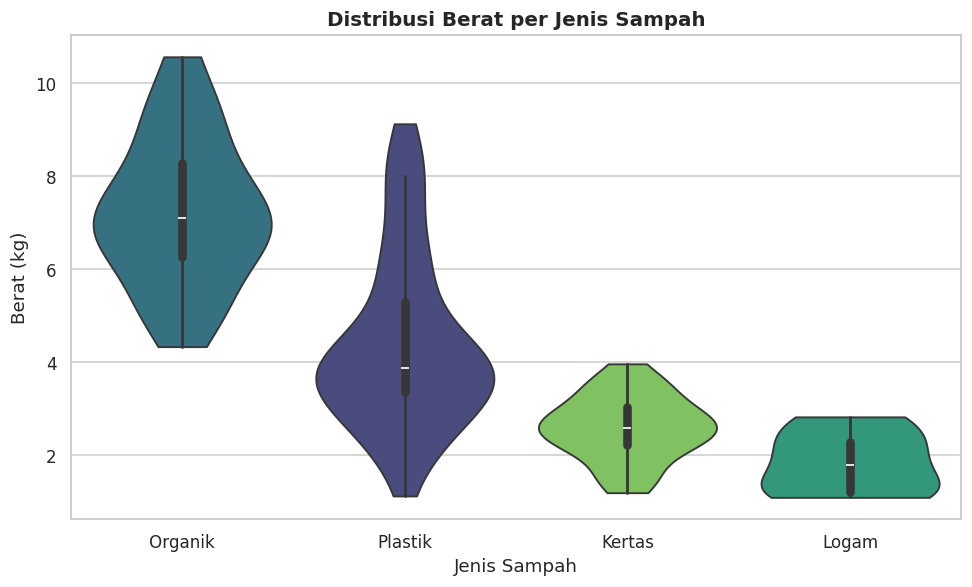

In [13]:
urut_jenis = df.groupby("Jenis Sampah")["Berat (kg)"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.violinplot(data=df, x="Jenis Sampah", y="Berat (kg)", order=urut_jenis, palette=PALET, hue="Jenis Sampah",
               legend=False, inner="box", cut=0, ax=ax)
ax.set_title("Distribusi Berat per Jenis Sampah")
plt.tight_layout()
plt.show()

**Keterangan:** bentuk *violin* menunjukkan sebaran data, garis tengah pada kotak kecil adalah median. Jenis dengan bentuk melebar ke atas berarti beratnya bervariasi besar.
**Organik** punya median tertinggi (7,10 kg, rentang 4,34 sampai 10,57 kg). **Plastik** sebarannya paling lebar (1,13 sampai 9,13 kg, median 3,88 kg). **Kertas** median 2,60 kg dan **Logam** median 1,80 kg. Jenis **Logam** hanya punya 10 data, jadi bentuknya kurang bisa diandalkan.

## 13. Dashboard Ringkas

Gabungan empat grafik utama dalam satu halaman, cocok untuk dimasukkan ke laporan atau slide presentasi.

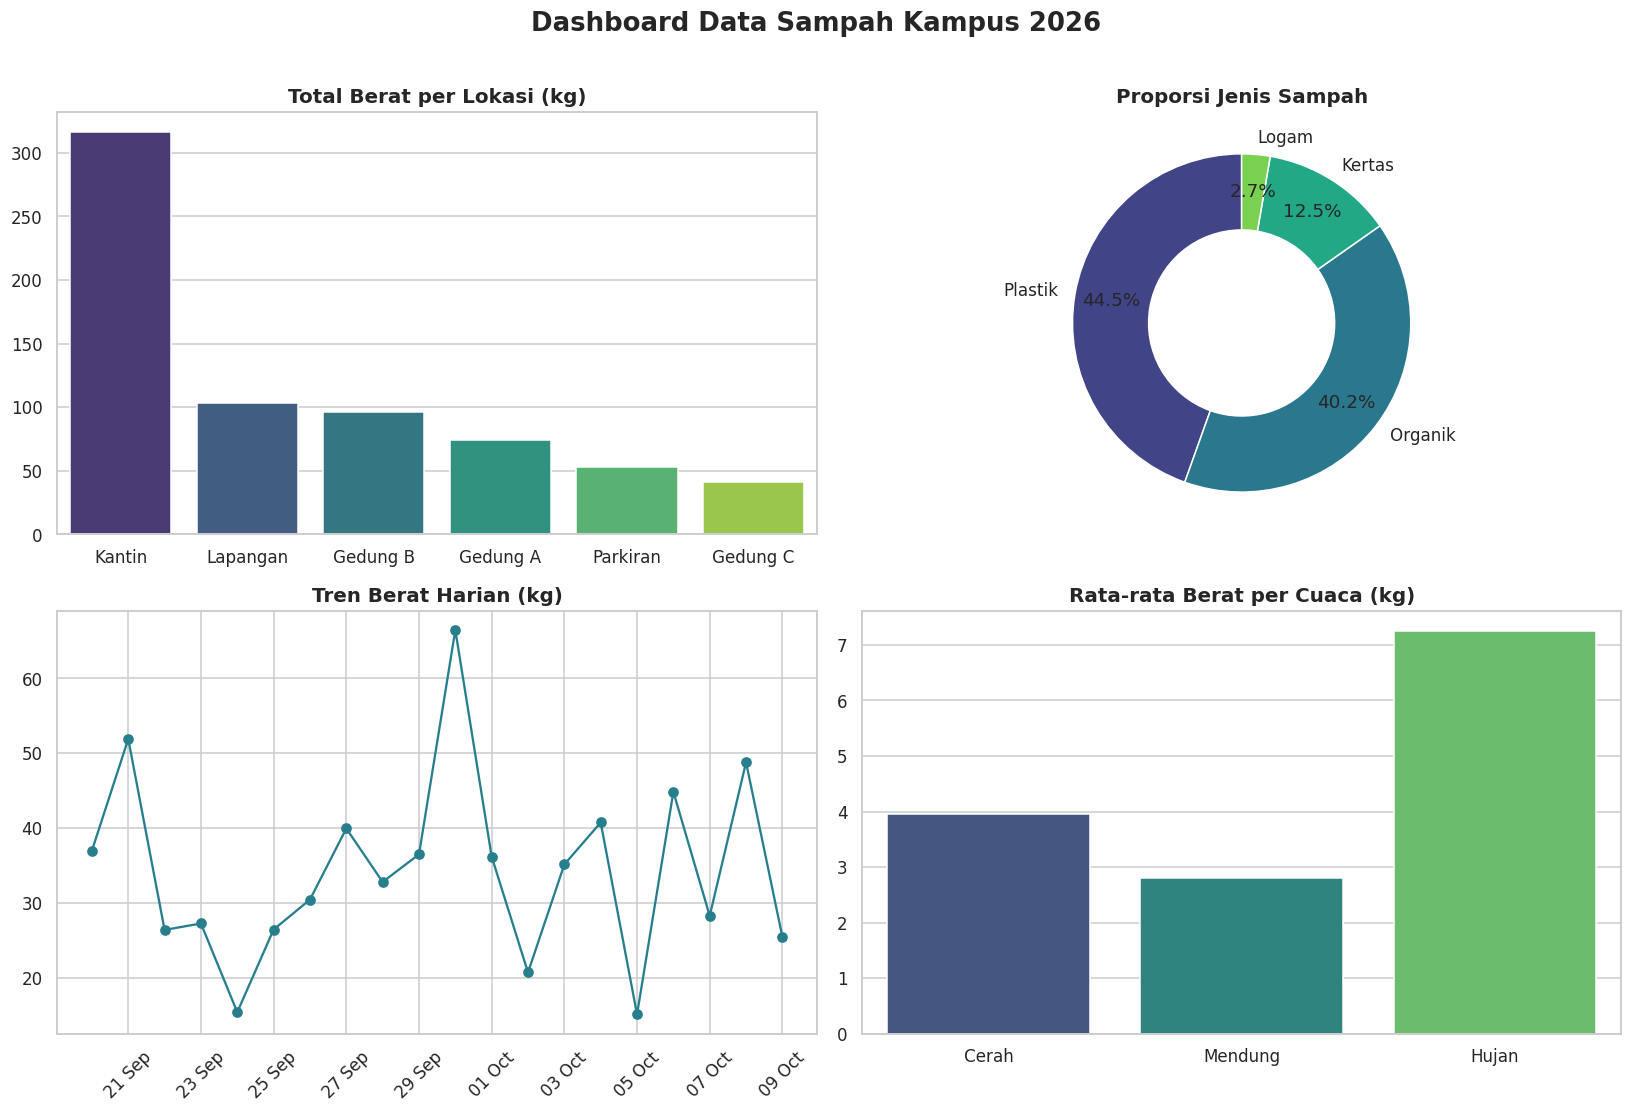

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Lokasi
sns.barplot(x=per_lokasi.index, y=per_lokasi.values, palette=PALET, hue=per_lokasi.index, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Total Berat per Lokasi (kg)")
axes[0, 0].set_xlabel("")

# 2. Jenis sampah
axes[0, 1].pie(per_jenis.values, labels=per_jenis.index, colors=warna, autopct="%1.1f%%",
               startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"), pctdistance=0.78)
axes[0, 1].set_title("Proporsi Jenis Sampah")

# 3. Tren harian
axes[1, 0].plot(harian.index, harian.values, marker="o", color=sns.color_palette(PALET)[2])
axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1, 0].set_title("Tren Berat Harian (kg)")
plt.setp(axes[1, 0].get_xticklabels(), rotation=45)

# 4. Cuaca
sns.barplot(x=rata.index, y=rata.values, palette=PALET, hue=rata.index, legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Rata-rata Berat per Cuaca (kg)")
axes[1, 1].set_xlabel("")

fig.suptitle("Dashboard Data Sampah Kampus 2026", fontsize=17, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 14. Kesimpulan

1. **Kantin** adalah sumber sampah terbesar (316,6 kg dari total sekitar 685 kg, atau 46%), jadi prioritas utama pengelolaan sampah.
2. **Plastik dan Organik** mendominasi (sekitar 85% berat), sehingga program pemilahan dan daur ulang paling berdampak jika fokus ke dua jenis ini.
3. Sampah paling banyak muncul saat **Istirahat** dan **Acara**, serta pada hari **hujan**. Hampir semua pencatatan hujan berasal dari Kantin, jadi perlu dicek lagi apakah itu efek cuaca atau efek lokasi.
4. Sekitar **68%** pencatatan menunjukkan tempat sampah sudah Penuh atau Meluber, sehingga perlu **tambahan tempat sampah** atau **pengangkutan lebih sering**, terutama di Kantin dan Lapangan.
5. Jumlah item dan berat berkorelasi positif cukup kuat (r ≈ 0,68), sehingga menghitung jumlah item bisa jadi perkiraan kasar berat sampah, tetapi tidak presisi.

**Keterbatasan:** data berisi 150 pencatatan selama 20 hari, jumlah pencatatan per hari tidak sama (3 sampai 11), dan beberapa kategori (misalnya Logam, 10 data) masih sedikit. Kesimpulan di atas bersifat indikatif dan akan lebih kuat jika periode pengamatan diperpanjang.